In [1]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

con = duckdb.connect("../data/processed/flights.duckdb")

def q(sql):
    return con.execute(sql).df()

In [2]:
q("""
SELECT COUNT(*) AS flights,
       MIN(FlightDate) AS first_date,
       MAX(FlightDate) AS last_date,
       COUNT(DISTINCT Reporting_Airline) AS airlines,
       COUNT(DISTINCT Origin) AS airports,
       COUNT(DISTINCT Tail_Number) AS aircraft
FROM read_csv_auto('../data/raw/*.csv', union_by_name=true)
""")

,flights,first_date,last_date,airlines,airports,aircraft
0,3446676,2025-01-01,2025-06-30,14,346,5930


In [3]:
q("SELECT * FROM read_csv_auto('../data/raw/*.csv', union_by_name=true) LIMIT 1").columns.tolist()

['Year',
 'Quarter',
 'Month',
 'DayofMonth',
 'DayOfWeek',
 'FlightDate',
 'Reporting_Airline',
 'DOT_ID_Reporting_Airline',
 'IATA_CODE_Reporting_Airline',
 'Tail_Number',
 'Flight_Number_Reporting_Airline',
 'OriginAirportID',
 'OriginAirportSeqID',
 'OriginCityMarketID',
 'Origin',
 'OriginCityName',
 'OriginState',
 'OriginStateFips',
 'OriginStateName',
 'OriginWac',
 'DestAirportID',
 'DestAirportSeqID',
 'DestCityMarketID',
 'Dest',
 'DestCityName',
 'DestState',
 'DestStateFips',
 'DestStateName',
 'DestWac',
 'CRSDepTime',
 'DepTime',
 'DepDelay',
 'DepDelayMinutes',
 'DepDel15',
 'DepartureDelayGroups',
 'DepTimeBlk',
 'TaxiOut',
 'WheelsOff',
 'WheelsOn',
 'TaxiIn',
 'CRSArrTime',
 'ArrTime',
 'ArrDelay',
 'ArrDelayMinutes',
 'ArrDel15',
 'ArrivalDelayGroups',
 'ArrTimeBlk',
 'Cancelled',
 'CancellationCode',
 'Diverted',
 'CRSElapsedTime',
 'ActualElapsedTime',
 'AirTime',
 'Flights',
 'Distance',
 'DistanceGroup',
 'CarrierDelay',
 'WeatherDelay',
 'NASDelay',
 'SecurityD

In [8]:
con.execute("DROP TABLE IF EXISTS flights")
con.execute("""
CREATE TABLE flights AS
SELECT
    CAST(FlightDate AS DATE)              AS flight_date,
    Reporting_Airline                     AS carrier,
    Tail_Number                           AS tail,
    Flight_Number_Reporting_Airline       AS flight_num,
    Origin, Dest,
    TRY_CAST(Distance AS DOUBLE)          AS Distance,
    TRY_CAST(CRSDepTime AS INTEGER)       AS CRSDepTime,
    TRY_CAST(CRSArrTime AS INTEGER)       AS CRSArrTime,
    TRY_CAST(CRSElapsedTime AS DOUBLE)    AS CRSElapsedTime,
    TRY_CAST(DepDelay AS DOUBLE)          AS DepDelay,
    TRY_CAST(ArrDelay AS DOUBLE)          AS ArrDelay,
    TRY_CAST(ArrDel15 AS DOUBLE)          AS ArrDel15,
    Cancelled, Diverted
FROM read_csv_auto('../data/raw/*.csv', union_by_name=true)
WHERE TRY_CAST(Cancelled AS DOUBLE) = 0
  AND TRY_CAST(Diverted AS DOUBLE) = 0
  AND Tail_Number IS NOT NULL
""")

print(q("SELECT COUNT(*) AS kept FROM flights"))
q("DESCRIBE flights")

      kept
0  3385822


,column_name,column_type,null,key,default,extra
0,flight_date,DATE,YES,None,None,None
1,carrier,VARCHAR,YES,None,None,None
2,tail,VARCHAR,YES,None,None,None
3,flight_num,BIGINT,YES,None,None,None
4,Origin,VARCHAR,YES,None,None,None
5,Dest,VARCHAR,YES,None,None,None
6,Distance,DOUBLE,YES,None,None,None
7,CRSDepTime,INTEGER,YES,None,None,None
8,CRSArrTime,INTEGER,YES,None,None,None
9,CRSElapsedTime,DOUBLE,YES,None,None,None


In [9]:
q("""
SELECT SUM(Cancelled) AS cancelled,
       SUM(Diverted) AS diverted,
       COUNT(*) AS total
FROM read_csv_auto('../data/raw/*.csv', union_by_name=true)
""")

,cancelled,diverted,total
0,51634.0,9220.0,3446676


In [10]:
q("""
SELECT COUNT(*) AS flights,
       AVG(ArrDel15) AS pct_delayed,
       AVG(ArrDelay) AS mean_delay_min,
       MEDIAN(ArrDelay) AS median_delay_min
FROM flights
""")

,flights,pct_delayed,mean_delay_min,median_delay_min
0,3385822,0.218946,7.897115,-6.0


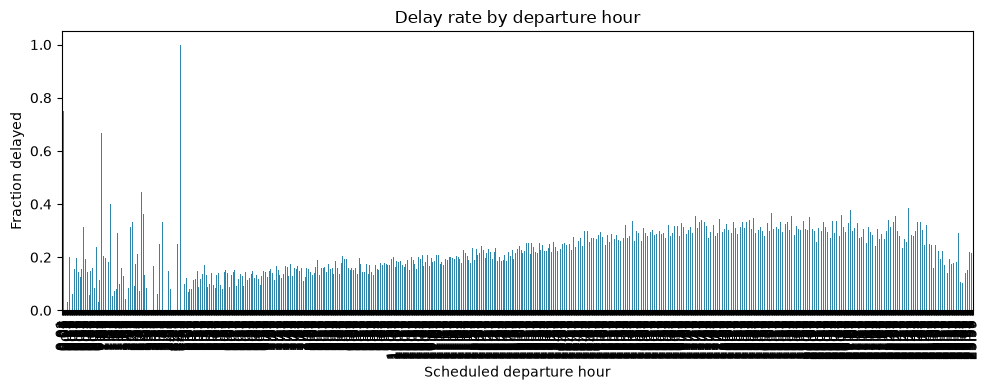

In [11]:
by_hour = q("""
SELECT CRSDepTime / 100 AS dep_hour,
       COUNT(*) AS flights,
       AVG(ArrDel15) AS pct_delayed
FROM flights
GROUP BY 1 ORDER BY 1
""")

by_hour.plot(x="dep_hour", y="pct_delayed", kind="bar", figsize=(10,4),
             legend=False, color="#2e86ab")
plt.ylabel("Fraction delayed")
plt.xlabel("Scheduled departure hour")
plt.title("Delay rate by departure hour")
plt.tight_layout()
plt.savefig("../figures/01_delay_by_hour.png", dpi=200)
plt.show()

In [12]:
q("""
SELECT carrier, COUNT(*) AS flights, AVG(ArrDel15) AS pct_delayed
FROM flights GROUP BY 1 HAVING COUNT(*) > 10000 ORDER BY 3 DESC
""")

,carrier,flights,pct_delayed
0,OH,119171,0.298865
1,F9,97323,0.285287
2,AA,470269,0.246912
3,G4,67312,0.245721
4,B6,113871,0.244276
5,AS,115384,0.223870
6,MQ,138583,0.215243
7,OO,404563,0.209115
8,DL,491130,0.207308
9,UA,381020,0.205601


In [13]:
q("""
SELECT date_trunc('month', flight_date) AS month,
       COUNT(*) AS flights, AVG(ArrDel15) AS pct_delayed
FROM flights GROUP BY 1 ORDER BY 1
""")

,month,flights,pct_delayed
0,2025-01-01,522269,0.187892
1,2025-02-01,496476,0.207668
2,2025-03-01,592301,0.195904
3,2025-04-01,577730,0.196639
4,2025-05-01,597574,0.236018
5,2025-06-01,599472,0.282590


In [14]:
q("""
SELECT Origin, Dest, COUNT(*) AS flights, AVG(ArrDel15) AS pct_delayed
FROM flights GROUP BY 1,2 HAVING COUNT(*) > 2000 ORDER BY 3 DESC LIMIT 20
""")

,Origin,Dest,flights,pct_delayed
0,LGA,ORD,5565,0.242947
1,ORD,LGA,5551,0.248964
2,HNL,OGG,5397,0.090421
3,OGG,HNL,5394,0.109566
4,SFO,LAX,5356,0.176998
5,LAX,SFO,5348,0.214847
6,JFK,LAX,4889,0.184087
7,LAX,JFK,4879,0.181185
8,PHX,DEN,4773,0.239053
9,DEN,PHX,4694,0.255432


In [15]:
prop = q("""
WITH legs AS (
    SELECT tail, flight_date, CRSDepTime, ArrDelay, ArrDel15,
           LAG(ArrDelay) OVER (PARTITION BY tail, flight_date ORDER BY CRSDepTime) AS prev_delay
    FROM flights
)
SELECT
    CASE
      WHEN prev_delay IS NULL  THEN 'first leg of day'
      WHEN prev_delay < 0      THEN 'prev arrived early'
      WHEN prev_delay < 15     THEN 'prev 0-15 min late'
      WHEN prev_delay < 45     THEN 'prev 15-45 min late'
      WHEN prev_delay < 90     THEN 'prev 45-90 min late'
      ELSE                          'prev 90+ min late'
    END AS previous_flight,
    COUNT(*) AS flights,
    AVG(ArrDel15) AS pct_delayed
FROM legs
GROUP BY 1 ORDER BY 3
""")
print(prop)
prop.to_csv("../results/delay_propagation.csv", index=False)

       previous_flight  flights  pct_delayed
0   prev arrived early  1610081     0.127601
1     first leg of day   854910     0.145923
2   prev 0-15 min late   430848     0.212971
3  prev 15-45 min late   269151     0.500875
4    prev 90+ min late    99586     0.831372
5  prev 45-90 min late   121246     0.839219


In [16]:
q("""
WITH legs AS (
    SELECT tail, flight_date,
           ROW_NUMBER() OVER (PARTITION BY tail, flight_date ORDER BY CRSDepTime) AS leg_num
    FROM flights
)
SELECT leg_num, COUNT(*) AS flights, 
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct
FROM legs GROUP BY 1 ORDER BY 1
""")

,leg_num,flights,pct
0,1,854910,25.2
1,2,785191,23.2
2,3,663856,19.6
3,4,521233,15.4
4,5,306795,9.1
5,6,178355,5.3
6,7,48849,1.4
7,8,21346,0.6
8,9,2844,0.1
9,10,1442,0.0


In [19]:
print(q("""
SELECT CRSDepTime / 100 AS dep_hour, COUNT(*) AS flights, AVG(ArrDel15) AS pct_delayed
FROM flights GROUP BY 1 ORDER BY 1
""").to_string(index=False))

 dep_hour  flights  pct_delayed
     0.01        9     0.222222
     0.02        1     0.000000
     0.04       16     0.750000
     0.05       88     0.250000
     0.06        1     0.000000
     0.07        1     0.000000
     0.08       53     0.094340
     0.09       52     0.461538
     0.10       30     0.033333
     0.11       13     0.230769
     0.13       24     0.250000
     0.14       35     0.200000
     0.15      171     0.222222
     0.16       12     0.333333
     0.17        9     0.000000
     0.18       48     0.062500
     0.19        1     0.000000
     0.20       81     0.246914
     0.21       70     0.157143
     0.22       21     0.095238
     0.23       62     0.080645
     0.24       46     0.195652
     0.25      106     0.179245
     0.26        3     0.333333
     0.27       63     0.142857
     0.28       99     0.171717
     0.29       67     0.208955
     0.30      183     0.125683
     0.31       89     0.157303
     0.32       47     0.170213
     0.3

In [21]:
con.close()